# Proyecto K-means: segmentacion de distritos de California

Objetivo: agrupar los distritos del censo de California en 6 grupos con K-means, usando solo tres variables (`MedInc`, `Latitude`, `Longitude`), predecir el grupo de datos nuevos (test) y entrenar un modelo supervisado que reproduzca esa asignacion.

Reglas de trabajo: K-means no tiene etiquetas verdaderas, asi que no existe un "accuracy" del agrupamiento; se evalua con inercia, silueta, estabilidad y con la interpretacion de cada grupo. El test se separa antes de ajustar nada y solo se usa para asignar grupos. K-means mide distancias, por lo que las variables se escalan dentro de un `Pipeline`.

## Bloque 1: datos, variables y particion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

SEED = 42
datos = pd.read_csv("../housing.csv")

print("Filas y columnas:", datos.shape)
print("Nulos en total:", int(datos.isna().sum().sum()))
print("Filas duplicadas:", int(datos.duplicated().sum()))
print("Columnas:", list(datos.columns))

Filas y columnas: (20640, 9)
Nulos en total: 0
Filas duplicadas: 0
Columnas: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


El enunciado pide usar solo tres variables: el ingreso mediano del distrito (`MedInc`, en decenas de miles de dolares) y su ubicacion (`Latitude`, `Longitude`). Se seleccionan y se revisan sus rangos, porque K-means decide por distancia y las escalas importan.

In [2]:
variables = ["MedInc", "Latitude", "Longitude"]
X = datos[variables].copy()

print(X.agg(["min", "median", "max", "std"]).T.round(3).to_string())
print()
print("Correlaciones entre las tres variables:")
print(X.corr().round(3).to_string())

              min   median     max    std
MedInc       0.50    3.535   15.00  1.900
Latitude    32.54   34.260   41.95  2.136
Longitude -124.35 -118.490 -114.31  2.004

Correlaciones entre las tres variables:
           MedInc  Latitude  Longitude
MedInc      1.000    -0.080     -0.015
Latitude   -0.080     1.000     -0.925
Longitude  -0.015    -0.925      1.000


## Particion

Se separa el 20 % para test con `random_state` fijo. No hay etiqueta que estratificar. El conjunto de test no se usa para ajustar el agrupamiento: solo para ver si los grupos se mantienen en datos no vistos.

In [3]:
X_train, X_test = train_test_split(X, test_size=0.2, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
comparacion = pd.DataFrame({"train": X_train.median(), "test": X_test.median()}).round(3)
print("Mediana de cada variable:")
print(comparacion.to_string())

Train: (16512, 3) | Test: (4128, 3)
Mediana de cada variable:
             train    test
MedInc       3.546    3.50
Latitude    34.260   34.23
Longitude -118.510 -118.47


**Conclusion del bloque 1.** El dataset tiene 20640 distritos, sin nulos ni duplicados. Con las tres variables elegidas, train queda en 16512 filas y test en 4128, y las medianas de ambos conjuntos son casi iguales (ingreso 3.55 frente a 3.50; latitud 34.26 frente a 34.23), asi que la particion es representativa. Las tres variables tienen desviaciones parecidas (1.9, 2.1 y 2.0), por lo que la escala no es tan dispar como en otros problemas; aun asi se escalara dentro del `Pipeline`, porque con distancias euclidianas un cambio de 1 grado de latitud pesa igual que un cambio de 10000 dolares de ingreso, y esa equivalencia es una decision, no un hecho. Latitud y longitud estan correlacionadas (-0.93) porque California es una franja diagonal; eso es esperable y no se corrige: los grupos geograficos seguiran esa diagonal.

## Bloque 2: K-means con K = 6

El enunciado fija K = 6. Antes de ajustarlo se mira, solo como contexto, como se comportan la inercia (suma de distancias al cuadrado al centroide, siempre baja al subir K) y la silueta (de -1 a 1; mide si cada punto esta mas cerca de su grupo que de otro) para K de 2 a 10, con las variables escaladas. La silueta se calcula con una muestra de 5000 puntos para no pagar el coste completo.

    inercia  silueta
K                   
2     21504    0.543
3     15247    0.511
4     11639    0.433
5      9509    0.388
6      8069    0.401
7      7021    0.370
8      6202    0.349
9      5631    0.357
10     5117    0.339


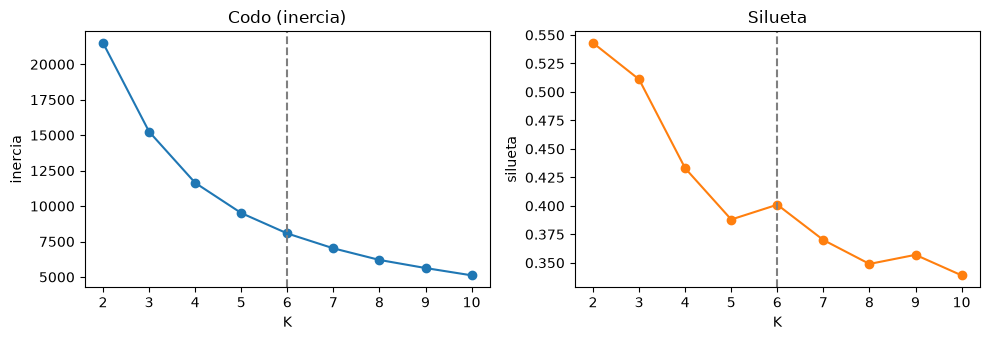

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

escalador = StandardScaler().fit(X_train)
Xs = escalador.transform(X_train)

filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    sil = silhouette_score(Xs, km.labels_, sample_size=5000, random_state=SEED)
    filas.append({"K": k, "inercia": round(km.inertia_), "silueta": round(sil, 3)})
contexto = pd.DataFrame(filas).set_index("K")
print(contexto.to_string())

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ejes[0].plot(contexto.index, contexto["inercia"], marker="o")
ejes[0].axvline(6, color="gray", linestyle="--")
ejes[0].set(xlabel="K", ylabel="inercia", title="Codo (inercia)")
ejes[1].plot(contexto.index, contexto["silueta"], marker="o", color="tab:orange")
ejes[1].axvline(6, color="gray", linestyle="--")
ejes[1].set(xlabel="K", ylabel="silueta", title="Silueta")
plt.tight_layout()
plt.show()

La inercia baja de forma continua, sin un codo claro. La silueta es mucho mayor con K = 2 (0.54) que con K = 6 (0.40), aunque K = 6 es un maximo local frente a K = 5 y K = 7. Es decir, estos datos no tienen una estructura de 6 grupos bien separados: son una nube continua que K-means reparte en zonas. K = 6 se mantiene porque lo pide el enunciado, y los grupos se interpretaran como segmentos utiles (zona + nivel de ingreso), no como clases naturales.

Otro punto: con `n_init=1` K-means depende de donde caen los centroides iniciales. Se comprueba la estabilidad comparando soluciones con distintas semillas mediante el indice de Rand ajustado (ARI: 1 = mismos grupos; cerca de 0 = distintos).

In [5]:
def estabilidad(n_init, semillas=range(5)):
    etiquetas = [KMeans(n_clusters=6, n_init=n_init, random_state=s).fit_predict(Xs) for s in semillas]
    pares = [adjusted_rand_score(etiquetas[i], etiquetas[j])
             for i in range(len(etiquetas)) for j in range(i + 1, len(etiquetas))]
    return round(min(pares), 3), round(float(np.mean(pares)), 3)

for n in (1, 10):
    minimo, medio = estabilidad(n)
    print(f"n_init={n:>2}: ARI minimo {minimo} | ARI medio {medio} (5 semillas, K=6)")

n_init= 1: ARI minimo 0.593 | ARI medio 0.741 (5 semillas, K=6)


n_init=10: ARI minimo 0.972 | ARI medio 0.989 (5 semillas, K=6)


## Modelo final

Se ajusta un `Pipeline` (escalado + K-means, K = 6, `n_init=10`) solo con train. El modelo guarda el escalador, asi que `predict` aplica a datos nuevos la misma transformacion. Luego se describe cada grupo con su tamano y las medianas de las tres variables.

In [6]:
modelo_kmeans = Pipeline([
    ("escalador", StandardScaler()),
    ("kmeans", KMeans(n_clusters=6, n_init=10, random_state=SEED)),
])
modelo_kmeans.fit(X_train)

train_cl = X_train.copy()
train_cl["cluster"] = modelo_kmeans.predict(X_train)

perfil = train_cl.groupby("cluster").agg(
    distritos=("MedInc", "size"),
    ingreso_mediano=("MedInc", "median"),
    latitud=("Latitude", "median"),
    longitud=("Longitude", "median"),
).round(2)
perfil["% del train"] = (100 * perfil["distritos"] / len(train_cl)).round(1)
print(perfil.sort_values("ingreso_mediano", ascending=False).to_string())
print()
print("Inercia final (en escala estandarizada):", round(modelo_kmeans.named_steps["kmeans"].inertia_))

         distritos  ingreso_mediano  latitud  longitud  % del train
cluster                                                            
2              453            10.12    34.11   -118.43          2.7
4             2239             5.22    37.68   -122.02         13.6
1             3380             5.10    33.92   -118.04         20.5
3             3931             2.89    38.01   -121.98         23.8
5             5188             2.85    33.97   -118.07         31.4
0             1321             2.56    36.30   -119.71          8.0

Inercia final (en escala estandarizada): 8069


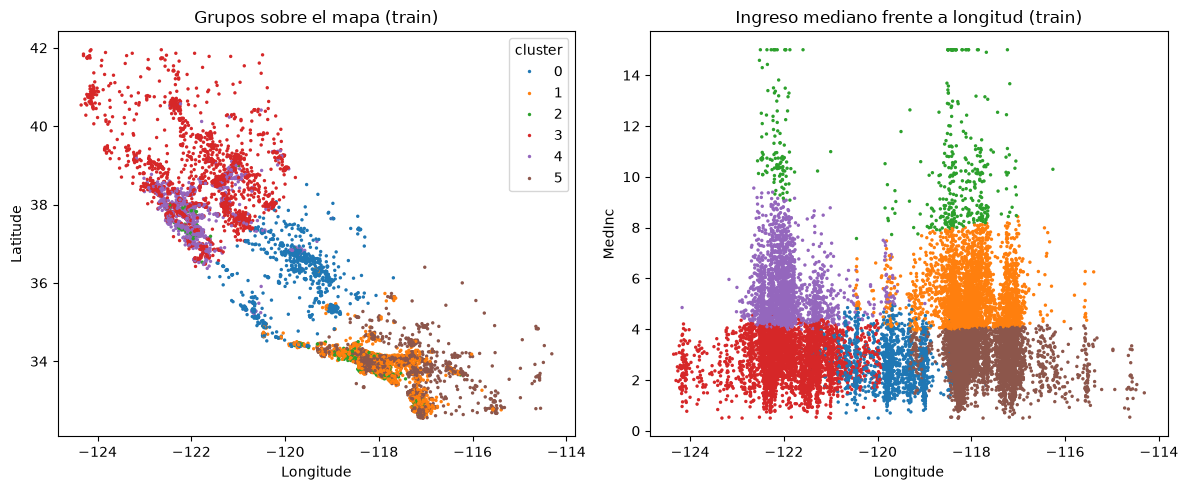

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=train_cl, x="Longitude", y="Latitude", hue="cluster", palette="tab10",
                s=6, linewidth=0, ax=ejes[0])
ejes[0].set(title="Grupos sobre el mapa (train)")
sns.scatterplot(data=train_cl, x="Longitude", y="MedInc", hue="cluster", palette="tab10",
                s=6, linewidth=0, legend=False, ax=ejes[1])
ejes[1].set(title="Ingreso mediano frente a longitud (train)")
plt.tight_layout()
plt.show()

**Conclusion del bloque 2.** La inercia baja sin un codo claro y la silueta es mucho mayor con K = 2 (0.54) que con K = 6 (0.40), aunque K = 6 es un maximo local frente a K = 5 (0.39) y K = 7 (0.37). Los datos son una nube continua y K-means la reparte en zonas; K = 6 se mantiene porque lo fija el enunciado, y los grupos son segmentos utiles, no clases naturales. La estabilidad confirma la eleccion de `n_init=10`: con una sola inicializacion dos semillas pueden dar agrupaciones muy distintas (ARI minimo 0.59), con 10 el resultado es casi identico (0.97). Los seis grupos son interpretables: uno de ingreso muy alto en Los Angeles (453 distritos, mediana 10.1), dos de ingreso medio-alto (Bahia de San Francisco, 5.2, y el sur de Los Angeles, 5.1) y tres de ingreso bajo (costa sur, norte de California y valle central, entre 2.6 y 2.9). El mapa muestra que el ingreso corta los grupos en umbrales (alrededor de 4 y de 8), lo que indica que en este espacio el ingreso pesa tanto como la ubicacion.

## Bloque 3: asignar grupos al conjunto de test

Se usa `predict` del `Pipeline` ajustado con train: aplica el mismo escalador y asigna cada distrito de test al centroide mas cercano. No se reajusta nada con test. Como no existen etiquetas verdaderas, no se puede medir un acierto; la comprobacion razonable es que los datos nuevos se reparten entre los grupos con proporciones y distancias al centroide parecidas a las de train.

In [8]:
test_cl = X_test.copy()
test_cl["cluster"] = modelo_kmeans.predict(X_test)

reparto = pd.DataFrame({
    "% train": (100 * train_cl["cluster"].value_counts(normalize=True)).round(1),
    "% test": (100 * test_cl["cluster"].value_counts(normalize=True)).round(1),
}).sort_index()
reparto["diferencia (pts)"] = (reparto["% test"] - reparto["% train"]).round(1)
print(reparto.to_string())
print()

# distancia de cada distrito a su centroide (en escala estandarizada)
def distancia_al_centroide(datos, etiquetas):
    Z = modelo_kmeans.named_steps["escalador"].transform(datos)
    centros = modelo_kmeans.named_steps["kmeans"].cluster_centers_
    return np.linalg.norm(Z - centros[etiquetas], axis=1)

d_train = distancia_al_centroide(X_train, train_cl["cluster"].to_numpy())
d_test = distancia_al_centroide(X_test, test_cl["cluster"].to_numpy())
print("Distancia media al centroide: train", round(d_train.mean(), 3), "| test", round(d_test.mean(), 3))
print("Percentil 95: train", round(np.percentile(d_train, 95), 3), "| test", round(np.percentile(d_test, 95), 3))

         % train  % test  diferencia (pts)
cluster                                   
0            8.0     8.2               0.2
1           20.5    20.1              -0.4
2            2.7     2.7               0.0
3           23.8    23.3              -0.5
4           13.6    12.5              -1.1
5           31.4    33.3               1.9

Distancia media al centroide: train 0.609 | test 0.602
Percentil 95: train 1.262 | test 1.227


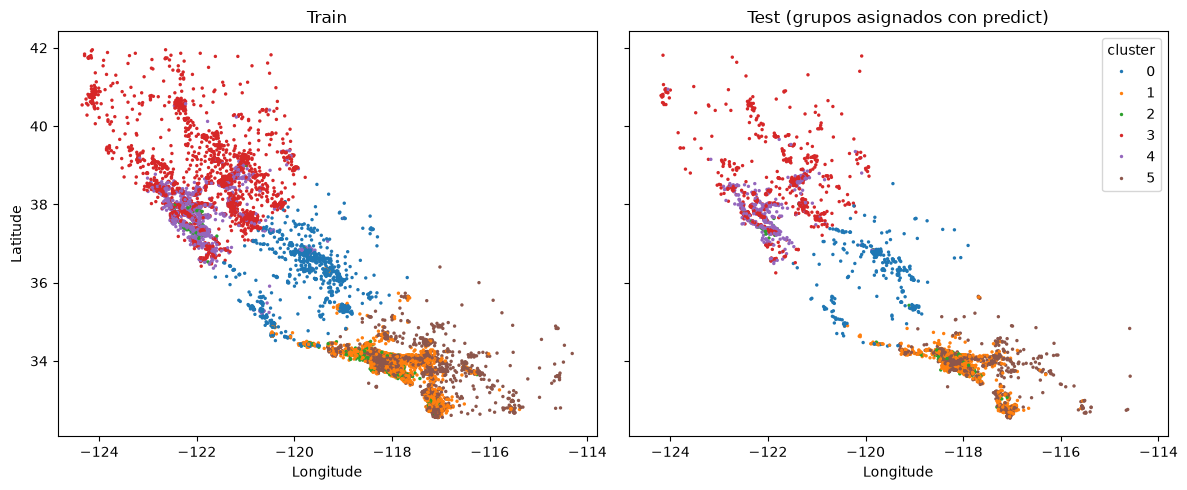

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for eje, datos_cl, titulo in ((ejes[0], train_cl, "Train"), (ejes[1], test_cl, "Test (grupos asignados con predict)")):
    sns.scatterplot(data=datos_cl, x="Longitude", y="Latitude", hue="cluster", palette="tab10",
                    s=6, linewidth=0, legend=(eje is ejes[1]), ax=eje)
    eje.set(title=titulo)
plt.tight_layout()
plt.show()

**Conclusion del bloque 3.** Al asignar los 4128 distritos de test con `predict`, el reparto entre grupos es casi el de train: la mayor diferencia es de 1.9 puntos porcentuales (el grupo 5 pasa de 31.4 % a 33.3 %) y el resto queda por debajo de 1.1. La distancia media al centroide es 0.609 en train y 0.602 en test, y el percentil 95 es 1.262 frente a 1.227. Los datos nuevos encajan en los grupos igual que los de train y los mapas muestran las mismas zonas. Esto no es un acierto medido (no hay etiquetas verdaderas): solo indica que el agrupamiento no esta sobreajustado a train y que los grupos se mantienen en datos no vistos.

## Bloque 4: modelo supervisado que predice el grupo

Ahora se entrena un clasificador que, a partir de las tres variables originales (`MedInc`, `Latitude`, `Longitude`), prediga el grupo asignado por K-means. La columna `cluster` no se usa como variable de entrada: solo es la etiqueta a predecir. Meter el grupo como variable haria trivial el problema (el modelo leeria la respuesta y el accuracy seria exactamente 1.0 sin aprender nada).

Se comparan un arbol de decision con varias profundidades, KNN y regresion logistica (estos dos con escalado dentro del `Pipeline`) mediante validacion cruzada estratificada de 5 folds sobre train. El test se usa una sola vez al final. Hay que tener claro que la etiqueta es la salida de otro modelo: un buen resultado mide si el modelo supervisado imita a K-means, no si los grupos son correctos.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

y_train = train_cl["cluster"]
y_test = test_cl["cluster"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
candidatos = {
    "arbol prof. 3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "arbol prof. 5": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "arbol prof. 8": DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "arbol prof. 12": DecisionTreeClassifier(max_depth=12, random_state=SEED),
    "arbol sin limite": DecisionTreeClassifier(random_state=SEED),
    "KNN k=15 (escalado)": Pipeline([("esc", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=15))]),
    "regresion logistica (escalado)": Pipeline([("esc", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))]),
}

filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    filas.append({"modelo": nombre,
                  "accuracy CV": round(r["test_accuracy"].mean(), 4),
                  "desv.": round(r["test_accuracy"].std(), 4),
                  "F1 macro CV": round(r["test_f1_macro"].mean(), 4)})
comparacion = pd.DataFrame(filas).set_index("modelo")
print(comparacion.to_string())

                                accuracy CV   desv.  F1 macro CV
modelo                                                          
arbol prof. 3                        0.9613  0.0014       0.9474
arbol prof. 5                        0.9817  0.0009       0.9752
arbol prof. 8                        0.9898  0.0009       0.9842
arbol prof. 12                       0.9918  0.0008       0.9879
arbol sin limite                     0.9919  0.0008       0.9881
KNN k=15 (escalado)                  0.9882  0.0020       0.9841
regresion logistica (escalado)       0.9901  0.0018       0.9834


Con la validacion cruzada se elige el modelo mas simple que quede dentro de una desviacion estandar del mejor, para no pagar complejidad por una diferencia que es ruido. Se ajusta con todo train y se evalua una unica vez en test.

In [11]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

mejor = comparacion["accuracy CV"].idxmax()
umbral = comparacion.loc[mejor, "accuracy CV"] - comparacion.loc[mejor, "desv."]
elegidos = [m for m in comparacion.index if comparacion.loc[m, "accuracy CV"] >= umbral]
print("Mejor en CV:", mejor)
print("Dentro de una desviacion del mejor:", elegidos)

nombre_final = elegidos[0]
modelo_supervisado = candidatos[nombre_final].fit(X_train, y_train)
print("Modelo elegido (el mas simple de esa lista):", nombre_final)
if hasattr(modelo_supervisado, "get_n_leaves"):
    print("Hojas del arbol:", modelo_supervisado.get_n_leaves(), "| profundidad real:", modelo_supervisado.get_depth())

Mejor en CV: arbol sin limite
Dentro de una desviacion del mejor: ['arbol prof. 12', 'arbol sin limite']
Modelo elegido (el mas simple de esa lista): arbol prof. 12
Hojas del arbol: 134 | profundidad real: 12


Accuracy en test: 0.9939
F1 macro en test: 0.9902

              precision    recall  f1-score   support

           0      0.991     0.979     0.985       337
           1      0.993     0.993     0.993       829
           2      0.991     0.964     0.977       112
           3      0.996     0.994     0.995       962
           4      0.988     0.998     0.993       514
           5      0.996     0.999     0.998      1374

    accuracy                          0.994      4128
   macro avg      0.993     0.988     0.990      4128
weighted avg      0.994     0.994     0.994      4128



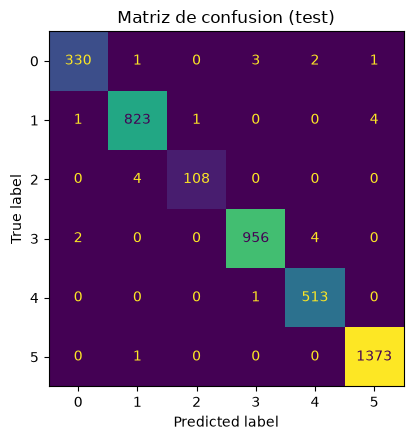

In [12]:
pred = modelo_supervisado.predict(X_test)
print("Accuracy en test:", round(accuracy_score(y_test, pred), 4))
print("F1 macro en test:", round(f1_score(y_test, pred, average="macro"), 4))
print()
print(classification_report(y_test, pred, digits=3))

fig, eje = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=eje, colorbar=False)
eje.set(title="Matriz de confusion (test)")
plt.tight_layout()
plt.show()

**Conclusion del bloque 4.** Un arbol de decision de profundidad 12 (134 hojas) reproduce la asignacion de K-means con accuracy 0.994 y F1 macro 0.990 en test, con las seis clases por encima de 0.96 de recall (la mas baja, el grupo 2 de ingreso muy alto, con solo 112 distritos en test). Eso mide que el modelo supervisado imita a K-means a partir de las tres variables originales, no que los grupos sean correctos: la etiqueta es la salida de otro modelo, y el 99 % es esperable porque las fronteras de K-means son rectas en el espacio escalado y se pueden aproximar con cortes sucesivos. En validacion cruzada la regresion logistica llego a 0.990 con muy pocos parametros, es decir, el mismo resultado con un modelo mucho mas simple; la regla de seleccion fijada de antemano eligio el arbol, y las dos opciones son validas. El accuracy de 1.0 de la solucion de referencia es un artefacto: alli el grupo se incluia como variable de entrada.

## Bloque 5: guardar los modelos

Se guardan con `pickle` en la carpeta `models/` con nombres que dicen que contiene cada uno: el `Pipeline` de K-means completo (incluye el escalador, asi que acepta las variables sin escalar) y el arbol que predice el grupo. Despues se cargan de nuevo y se comprueba que dan exactamente las mismas predicciones, para asegurar que lo guardado funciona.

In [13]:
import os
import pickle

os.makedirs("../models", exist_ok=True)
ruta_kmeans = "../models/kmeans_k6_escalado_medinc_lat_lon.pkl"
ruta_arbol = "../models/arbol_prof12_predice_cluster_kmeans.pkl"

with open(ruta_kmeans, "wb") as f:
    pickle.dump(modelo_kmeans, f)
with open(ruta_arbol, "wb") as f:
    pickle.dump(modelo_supervisado, f)

for ruta in (ruta_kmeans, ruta_arbol):
    print(ruta, "->", round(os.path.getsize(ruta) / 1024, 1), "KB")

with open(ruta_kmeans, "rb") as f:
    kmeans_cargado = pickle.load(f)
with open(ruta_arbol, "rb") as f:
    arbol_cargado = pickle.load(f)

print()
print("K-means cargado da los mismos grupos en test:", bool((kmeans_cargado.predict(X_test) == test_cl["cluster"]).all()))
print("Arbol cargado da las mismas predicciones en test:", bool((arbol_cargado.predict(X_test) == pred).all()))

../models/kmeans_k6_escalado_medinc_lat_lon.pkl -> 65.8 KB
../models/arbol_prof12_predice_cluster_kmeans.pkl -> 30.5 KB

K-means cargado da los mismos grupos en test: True
Arbol cargado da las mismas predicciones en test: True


In [14]:
def asignar_grupo(medinc, latitud, longitud):
    nuevo = pd.DataFrame({"MedInc": [medinc], "Latitude": [latitud], "Longitude": [longitud]})
    return int(kmeans_cargado.predict(nuevo)[0]), int(arbol_cargado.predict(nuevo)[0])

ejemplos = {
    "Los Angeles, ingreso muy alto": (11.0, 34.10, -118.40),
    "Bahia de San Francisco, ingreso medio-alto": (5.5, 37.70, -122.10),
    "Fresno, ingreso bajo": (2.5, 36.75, -119.80),
}
for nombre, valores in ejemplos.items():
    km, arbol = asignar_grupo(*valores)
    print(f"{nombre}: K-means grupo {km} | arbol grupo {arbol}")

Los Angeles, ingreso muy alto: K-means grupo 2 | arbol grupo 2
Bahia de San Francisco, ingreso medio-alto: K-means grupo 4 | arbol grupo 4
Fresno, ingreso bajo: K-means grupo 0 | arbol grupo 0


**Conclusion del bloque 5.** Los dos modelos quedan guardados en `models/` (el `Pipeline` de K-means de unos 66 KB y el arbol de unos 31 KB). Al cargarlos de nuevo dan exactamente los mismos grupos y las mismas predicciones en test, y en tres ejemplos con valores nuevos K-means y el arbol coinciden. El `Pipeline` incluye el escalador, asi que se puede usar con las variables sin escalar.

## Conclusion final

Se segmentaron 20640 distritos de California en 6 grupos con K-means usando solo ingreso mediano, latitud y longitud. Con las variables escaladas y `n_init=10` el resultado es estable (ARI minimo 0.97 entre semillas, frente a 0.59 con una sola inicializacion). Los seis grupos se interpretan como zona mas nivel de ingreso: un grupo de ingreso muy alto en Los Angeles (453 distritos, mediana 10.1), dos de ingreso medio-alto (Bahia de San Francisco y sur de Los Angeles, alrededor de 5.1) y tres de ingreso bajo (costa sur, norte y valle central, entre 2.6 y 2.9). Los 4128 distritos de test se reparten entre los grupos con proporciones y distancias al centroide casi iguales a las de train, asi que el agrupamiento se mantiene en datos nuevos.

Limites que conviene tener presentes. K = 6 viene fijado por el enunciado y no por los datos: la silueta es mayor con K = 2 (0.54 frente a 0.40) y la inercia no muestra un codo, de modo que los grupos son una particion util de una nube continua y no clases naturales. Tampoco hay etiquetas verdaderas, por lo que el agrupamiento no tiene un accuracy: se valora por estabilidad, interpretacion y comportamiento en datos no vistos.

El modelo supervisado (arbol de profundidad 12) predice el grupo con accuracy 0.994 y F1 macro 0.990 en test usando solo las tres variables originales. Ese numero mide que imita a K-means, no que los grupos sean correctos. Respecto a la solucion de referencia, aqui el grupo no se usa como variable de entrada (alli daba un 1.0 artificial), se escalan las variables, se usan 10 inicializaciones para fijar una solucion estable, el test se usa una sola vez y los modelos se guardan con rutas relativas.